# Classification

## Import des dépendances

In [1]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

I0000 00:00:1793674879.487109   36704 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793674879.525474   36704 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793674880.969504   36704 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1793674881.175066   36704 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



## Définition de la longueur et de la largeur de l'image

In [2]:
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

## Chargement des images

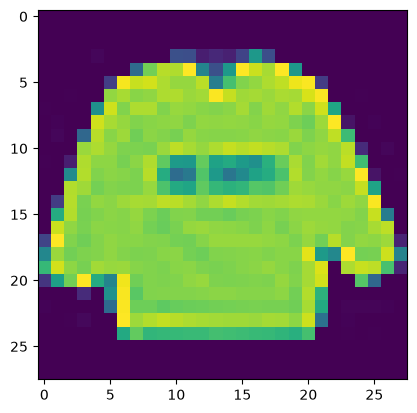

In [3]:
observations_entrainement = pnd.read_csv('data/fashion-mnist_train.csv')

#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## Préparation des données d’apprentissage

### Création des catégories à l'aide de Keras

In [4]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))

### Répartition des données d'entrainement en données d'apprentissage et données de validation

80% de données d'apprentissage et 20% de données de validation

In [5]:
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

## Reformater et transformer les données des images
Les données sont au format 28*28 et chaque pixel est transformé afin d'être compris dans une plage de valeurs entre 0 et 1.

In [6]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(
    X_apprentissage.shape[0],
    LARGEUR_IMAGE, 
    LONGUEUR_IMAGE, 1
)

X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(
    X_validation.shape[0],
    LARGEUR_IMAGE, 
    LONGUEUR_IMAGE, 1
)

X_validation = X_validation.astype('float32')
X_validation /= 255

## Préparer les données de tests
Les données sont préparées de la même manière que celles d'apprentissage.

In [7]:
# Préparation des données de tests
observations_test = pnd.read_csv('data/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

## Réseau avec une seule couche de convolution

### Configuration
La configuration de notre premier réseau de neurones à convolution va comporter les éléments suivants:

- Une couche de convolution de 32 filtres de taille 3x3 avec une fonction d’activation de type ReLU
- Un pooling composé d’un filtre de 2x2
- Une phase de flatten (mise en colonne des résultats du pooling)
- Un réseau de neurones complètement connecté de 128 neurones avec une fonction d’activation de type ReLU
- Un dernier réseau de neurones complètement connecté comportant 10 neurones et une fonction d’activation de type Softmax correspondant aux 10 catégories d’images à prédire

In [8]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

# 1- Ajout de la couche de convolution comportant
#    - 32 filtres de de taille 3x3 (Kernel) parcourant l'image
#    - Une fonction d'activation de type ReLU (Rectified Linear Activation)
#    - Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(
    Conv2D(
        32, 
        kernel_size=(3, 3), 
        activation='relu'
    )
)

# 2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

# 3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

# 5- On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

# 6- Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

# 7- Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

### Compilation
La compilation se fait en précisant la fonction de minimisation de l'erreur, l'optimiseur (algorithme Adam) et la valeur mesurée (la précision).

In [9]:
reseauNeurone1Convolution.compile(
    loss=keras.losses.categorical_crossentropy, 
    optimizer=tf.keras.optimizers.Adam(), 
    metrics=['accuracy']
)

### Apprentissage
10 passages complets du jeu de données (epochs), 256 images traitées à la fois (batch_size), validation sur les 20% de données de validation.

In [10]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 13s 62ms/step - accuracy: 0.8131 - loss: 0.5371 - val_accuracy: 0.8630 - val_loss: 0.3904
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 62ms/step - accuracy: 0.8785 - loss: 0.3454 - val_accuracy: 0.8873 - val_loss: 0.3241
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.8920 - loss: 0.3046 - val_accuracy: 0.8922 - val_loss: 0.3049
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.9003 - loss: 0.2801 - val_accuracy: 0.8876 - val_loss: 0.3065
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.9053 - loss: 0.2634 - val_accuracy: 0.8969 - val_loss: 0.2817
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.9116 - loss: 0.2456 - val_accuracy: 0.9032 - val_loss: 0.2636
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 58ms/step - accuracy: 0.9161 - loss: 0.2311 - val_accuracy: 0.9061 - val_loss: 0.2609
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.9211 - loss: 0.2180 - 

### Évaluation du modèle sur les données de tests

In [11]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.24011670053005219
Précision: 0.9143999814987183


### Courbes de précision et d'erreur

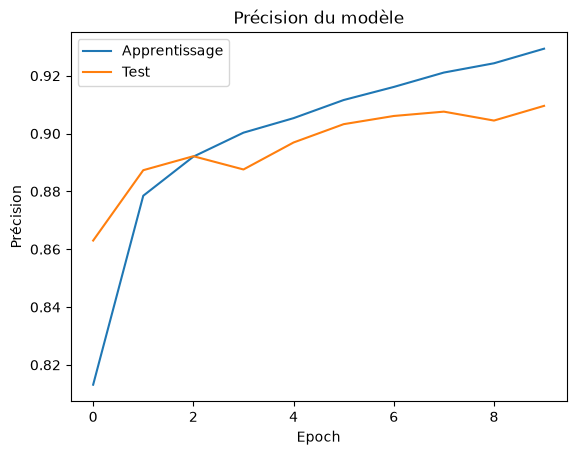

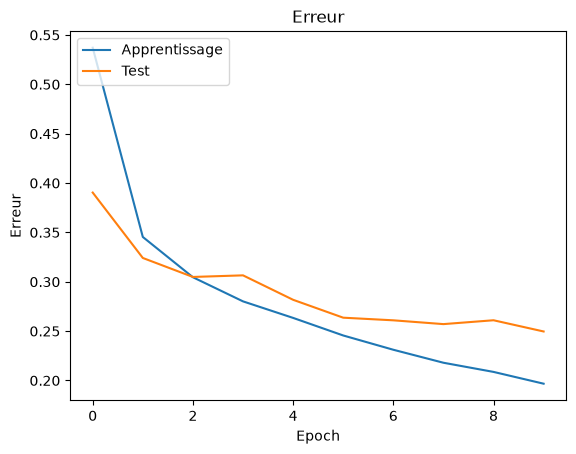

In [12]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

## Augmentation du nombre de données

### Générateur d'images
Création de nouvelles images par rotation, translation, cisaillement et zoom aléatoires des images d'apprentissage.

In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

### Génération des nouvelles images

In [14]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

### Nouvel apprentissage
50 epochs de 187 itérations (48 000 / 256).

In [15]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

Epoch 1/50


I0000 00:00:1793674996.726574   36704 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 25s 129ms/step - accuracy: 0.8286 - loss: 0.4568 - val_accuracy: 0.8369 - val_loss: 0.4290
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.8398 - loss: 0.3755

/home/ian/Workspace/Technologie/420-5G4-ML/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.8398 - loss: 0.3755 - val_accuracy: 0.8452 - val_loss: 0.4160
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 24s 126ms/step - accuracy: 0.8473 - loss: 0.4087 - val_accuracy: 0.8573 - val_loss: 0.3880
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.8398 - loss: 0.4192 - val_accuracy: 0.8604 - val_loss: 0.3848
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 23s 125ms/step - accuracy: 0.8565 - loss: 0.3850 - val_accuracy: 0.8584 - val_loss: 0.3785
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.8242 - loss: 0.4687 - val_accuracy: 0.8595 - val_loss: 0.3806
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 25s 132ms/step - accuracy: 0.8607 - loss: 0.3730 - val_accuracy: 0.8674 - val_loss: 0.3546
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9102 - loss: 0.2704 - val_accuracy: 0.8677 - val_loss: 0.3585
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 27s 146ms/step - accuracy: 0.8637 - loss: 0.3690 - val_accurac

### Évaluation du nouveau modèle sur les données de tests

In [16]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Erreur : 0.22373411059379578
Précision: 0.9207000136375427


## Sauvegarde du modèle
La définition du modèle est sauvegardée au format JSON et les poids dans un fichier H5, dans le répertoire `modele/`.

In [17]:
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)

# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !
